In [1]:
!pip install -q transformers pillow matplotlib requests nltk rouge-score pandas tqdm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import time
import requests
import torch
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import os
import json

from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm
from google.colab import files
from collections import defaultdict
from transformers import (
    BlipProcessor,
    BlipForConditionalGeneration
)

nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Selected Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Selected Device: cuda
GPU: Tesla T4


In [4]:
model_name = "Salesforce/blip-image-captioning-base"

processor = BlipProcessor.from_pretrained(model_name)

model = BlipForConditionalGeneration.from_pretrained(
    model_name
).to(device)

model.eval()

print("BLIP Large loaded successfully!")

predictions = []
references = []
inference_times = []


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

BLIP Large loaded successfully!


In [5]:

def generate_caption(image):

    image = image.convert("RGB")

    inputs = processor(
        images=image,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():

        output = model.generate(
            **inputs,
            max_new_tokens=40,
            num_beams=5,
            do_sample=False,
            repetition_penalty=1.1,
            no_repeat_ngram_size=2,
            early_stopping=True
        )

    caption = processor.decode(
        output[0],
        skip_special_tokens=True
    )

    return caption


In [6]:
# Create COCO directory
!mkdir -p /content/coco

# Remove previously corrupted ZIP
!rm -f /content/val2017.zip

# Download using SSL certificate workaround
!wget --no-check-certificate \
https://images.cocodataset.org/zips/val2017.zip \
-O /content/val2017.zip

# Verify and extract only if ZIP is valid
import zipfile
import os

zip_path = "/content/val2017.zip"

if zipfile.is_zipfile(zip_path):
    print("ZIP file verified successfully!")

    !unzip -q -o /content/val2017.zip -d /content/coco

    image_folder = "/content/coco/val2017"
    print("Total images:", len(os.listdir(image_folder)))
    print("COCO validation images extracted successfully!")

else:
    print("Download failed or ZIP file is corrupted.")


--2026-11-11 12:24:19--  https://images.cocodataset.org/zips/val2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 16.15.245.97, 16.15.183.52, 16.15.253.32, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|16.15.245.97|:443... connected.
	requested host name ‘images.cocodataset.org’.
HTTP request sent, awaiting response... 200 OK
Length: 815585330 (778M) [application/zip]
Saving to: ‘/content/val2017.zip’

/content/val2017.zi 100%[===================>] 777.80M  57.8MB/s    in 17s     

2026-11-11 12:24:36 (46.3 MB/s) - ‘/content/val2017.zip’ saved [815585330/815585330]

ZIP file verified successfully!
Total images: 5000
COCO validation images extracted successfully!


In [7]:
# Download annotations
!wget -q --show-progress \
http://images.cocodataset.org/annotations/annotations_trainval2017.zip \
-O /content/annotations.zip

# Extract annotations
!unzip -q /content/annotations.zip -d /content/coco

print("COCO annotations extracted!")

/content/annotation 100%[===================>] 241.19M  62.0MB/s    in 4.3s    
COCO annotations extracted!


In [8]:
annotation_path = (
    "/content/coco/annotations/captions_val2017.json"
)

image_directory = "/content/coco/val2017"

with open(annotation_path, "r") as f:
    coco_data = json.load(f)

# Group captions by image ID
caption_dict = defaultdict(list)

for annotation in coco_data["annotations"]:

    caption_dict[annotation["image_id"]].append(
        annotation["caption"]
    )

# Create image-caption records
coco_images = []

for item in coco_data["images"]:

    image_path = os.path.join(
        image_directory,
        item["file_name"]
    )

    coco_images.append({
        "image_id": item["id"],
        "image_path": image_path,
        "captions": caption_dict[item["id"]]
    })

print("Dataset loaded successfully!")
print("Total images:", len(coco_images))

print(
    "Total reference captions:",
    sum(len(x["captions"]) for x in coco_images)
)

Dataset loaded successfully!
Total images: 5000
Total reference captions: 25014


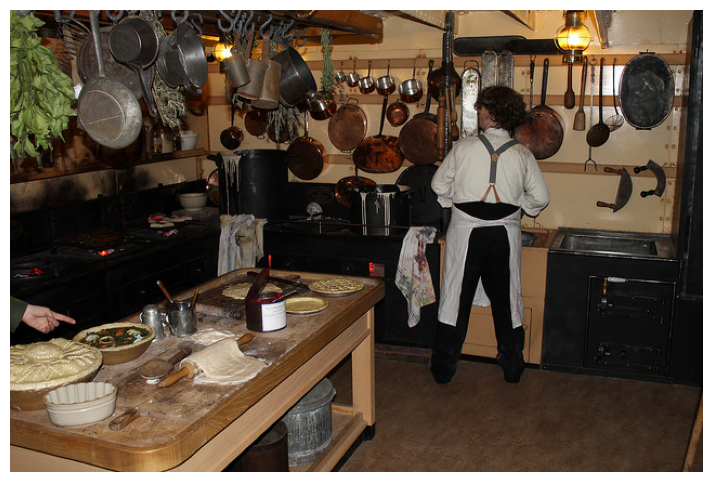

Human-written captions:

1. A man is in a kitchen making pizzas.
2. Man in apron standing on front of oven with pans and bakeware
3. A baker is working in the kitchen rolling dough.
4. A person standing by a stove in a kitchen.
5. A table with pies being made and a person standing near a wall with pots and pans hanging on the wall.


In [9]:
sample = coco_images[0]

image = Image.open(
    sample["image_path"]
).convert("RGB")

plt.figure(figsize=(9, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

print("Human-written captions:\n")

for i, caption in enumerate(sample["captions"]):
    print(f"{i+1}. {caption}")

In [11]:
NUM_IMAGES = len(coco_images)

predictions = []
references = []
inference_times = []

# Warm-up prediction
_ = generate_caption(
    Image.open(
        coco_images[0]["image_path"]
    ).convert("RGB")
)

# Reset memory statistics after warm-up
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

for i in tqdm(range(NUM_IMAGES)):

    sample = coco_images[i]

    image = Image.open(
        sample["image_path"]
    ).convert("RGB")

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    predicted_caption = generate_caption(image)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end_time = time.perf_counter()

    # Store inference time
    inference_times.append(end_time - start_time)

    # Store prediction
    predictions.append(predicted_caption)

    # Store human-written reference captions
    references.append(sample["captions"])

print("\nEvaluation completed!")
print("Total images evaluated:", len(predictions))

  0%|          | 0/5000 [00:00<?, ?it/s]


Evaluation completed!
Total images evaluated: 5000


In [12]:
from nltk.translate.bleu_score import (
    corpus_bleu,
    SmoothingFunction
)

# Tokenize generated captions
tokenized_predictions = [
    caption.lower().split()
    for caption in predictions
]

# Tokenize reference captions
tokenized_references = [
    [ref.lower().split() for ref in refs]
    for refs in references
]

smooth = SmoothingFunction().method1

# BLEU-1
bleu_1 = corpus_bleu(
    tokenized_references,
    tokenized_predictions,
    weights=(1, 0, 0, 0),
    smoothing_function=smooth
)

# BLEU-2
bleu_2 = corpus_bleu(
    tokenized_references,
    tokenized_predictions,
    weights=(0.5, 0.5, 0, 0),
    smoothing_function=smooth
)

# BLEU-4
bleu_4 = corpus_bleu(
    tokenized_references,
    tokenized_predictions,
    weights=(0.25, 0.25, 0.25, 0.25),
    smoothing_function=smooth
)

print("BLEU EVALUATION RESULTS")
print("-----------------------")
print(f"BLEU-1: {bleu_1:.4f}")
print(f"BLEU-2: {bleu_2:.4f}")
print(f"BLEU-4: {bleu_4:.4f}")

BLEU EVALUATION RESULTS
-----------------------
BLEU-1: 0.6327
BLEU-2: 0.5031
BLEU-4: 0.3053


In [13]:
from nltk.translate.meteor_score import meteor_score

meteor_scores = []

for refs, prediction in tqdm(
    zip(references, predictions),
    total=len(predictions)
):

    tokenized_refs = [
        ref.lower().split()
        for ref in refs
    ]

    tokenized_prediction = prediction.lower().split()

    score = meteor_score(
        tokenized_refs,
        tokenized_prediction
    )

    meteor_scores.append(score)

average_meteor = sum(meteor_scores) / len(meteor_scores)

print("METEOR Score:", round(average_meteor, 4))

  0%|          | 0/5000 [00:00<?, ?it/s]

METEOR Score: 0.4239


In [14]:
from rouge_score import rouge_scorer

scorer = rouge_scorer.RougeScorer(
    ["rougeL"],
    use_stemmer=True
)

rouge_scores = []

for refs, prediction in tqdm(
    zip(references, predictions),
    total=len(predictions)
):

    scores = [
        scorer.score(ref, prediction)["rougeL"].fmeasure
        for ref in refs
    ]

    rouge_scores.append(max(scores))

average_rouge = sum(rouge_scores) / len(rouge_scores)

print("ROUGE-L Score:", round(average_rouge, 4))

  0%|          | 0/5000 [00:00<?, ?it/s]

ROUGE-L Score: 0.5381


In [15]:
# Average inference time
avg_inference_time = sum(inference_times) / len(inference_times)

# Total measured inference time
total_inference_time = sum(inference_times)

# Images processed per second
throughput = len(predictions) / total_inference_time

# Model parameters
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

# Model parameter storage
model_size_mb = sum(
    p.numel() * p.element_size()
    for p in model.parameters()
) / (1024 ** 2)

# GPU memory
if torch.cuda.is_available():

    gpu_memory = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 2)
    )

else:
    gpu_memory = None

print("COMPUTATIONAL PERFORMANCE")
print("--------------------------")

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print(f"Parameter Storage: {model_size_mb:.2f} MB")

print(
    f"Average Inference Time: "
    f"{avg_inference_time:.4f} seconds"
)

print(f"Throughput: {throughput:.2f} images/second")

if gpu_memory is not None:
    print(f"Peak GPU Memory: {gpu_memory:.2f} MB")
else:
    print("Peak GPU Memory: Not available")

COMPUTATIONAL PERFORMANCE
--------------------------
Total Parameters: 223,971,644
Trainable Parameters: 223,971,644
Parameter Storage: 854.38 MB
Average Inference Time: 0.2578 seconds
Throughput: 3.88 images/second
Peak GPU Memory: 1096.56 MB


In [16]:
results = pd.DataFrame({

    "Evaluation Parameter": [
        "BLEU-1",
        "BLEU-2",
        "BLEU-4",
        "METEOR",
        "ROUGE-L",
        "Average Inference Time (sec)",
        "Throughput (images/sec)",
        "Total Model Parameters",
        "Trainable Parameters",
        "Model Parameter Storage (MB)",
        "Peak GPU Memory (MB)"
    ],

    "Result": [

        round(bleu_1, 4),
        round(bleu_2, 4),
        round(bleu_4, 4),
        round(average_meteor, 4),
        round(average_rouge, 4),

        round(avg_inference_time, 4),
        round(throughput, 2),

        total_params,
        trainable_params,

        round(model_size_mb, 2),

        round(gpu_memory, 2)
        if gpu_memory is not None
        else "N/A"
    ]
})

display(results)

results.to_csv(
    "BLIP_MS_COCO_Evaluation.csv",
    index=False
)

print("Evaluation report saved!")

,Evaluation Parameter,Result
0,BLEU-1,6.327000e-01
1,BLEU-2,5.031000e-01
2,BLEU-4,3.053000e-01
3,METEOR,4.239000e-01
4,ROUGE-L,5.381000e-01
5,Average Inference Time (sec),2.578000e-01
6,Throughput (images/sec),3.880000e+00
7,Total Model Parameters,2.239716e+08
8,Trainable Parameters,2.239716e+08
9,Model Parameter Storage (MB),8.543800e+02


Evaluation report saved!


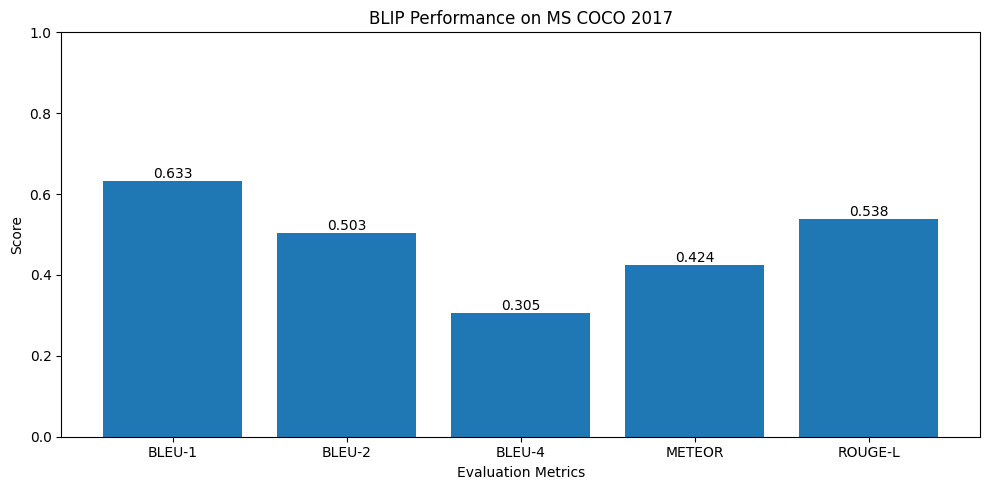

In [17]:
metrics = [
    "BLEU-1",
    "BLEU-2",
    "BLEU-4",
    "METEOR",
    "ROUGE-L"
]

scores = [
    bleu_1,
    bleu_2,
    bleu_4,
    average_meteor,
    average_rouge
]

plt.figure(figsize=(10, 5))

bars = plt.bar(metrics, scores)

plt.title("BLIP Performance on MS COCO 2017")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)

for bar, score in zip(bars, scores):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{score:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "BLIP_MS_COCO_Evaluation.png",
    dpi=300
)

plt.show()

Enter image path: /content/Test image 5.jpg


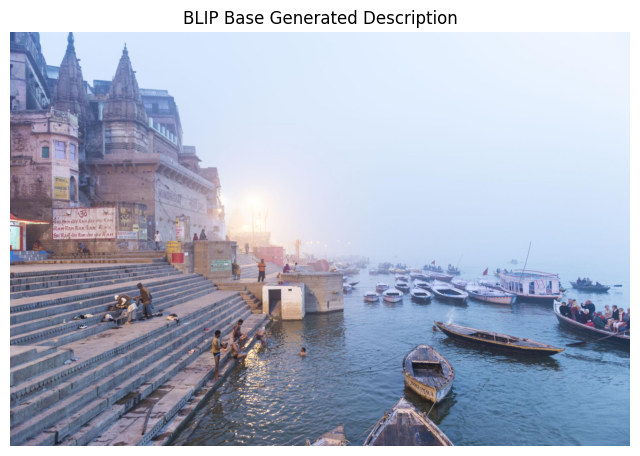


Generated Description:
a body of water


In [32]:
from PIL import Image
import matplotlib.pyplot as plt
import os
import torch


image_path = input("Enter image path: ").strip()


if not os.path.isfile(image_path):
    print("Error: Image file not found. Check the image path.")

else:
    try:
        test_image = Image.open(image_path).convert("RGB")


        generated_caption = generate_caption(test_image)


        plt.figure(figsize=(8, 6))
        plt.imshow(test_image)
        plt.axis("off")
        plt.title("BLIP Base Generated Description")
        plt.show()

        print("\nGenerated Description:")
        print(generated_caption)

    except Exception as e:
        print("Error processing image:", e)

